# Noise sources in a CCD image and Bias frame

An astrophysical image obtained with a CCD is characterised by four sources of noise:

1. **Read-out noise** (RON): Caused by electronic noise in the CCD output transistor and possibly also in the external circuitry. Read noise places a fundamental limit on the performance of a CCD. *It cannot be removed from the image.*
2. **Dark current** (DC). Caused by thermally generated electrons in the CCD. *Eliminated by cooling the CCD.*
3. **Photon noise** (PN) or *SHOT NOISE* (SN). Photons arrive in a random fashion described by [Poisson statistics](https://en.wikipedia.org/wiki/Poisson_distribution).
4. **Pixel response non-uniformity**. Difference in pixel sensitivity variations – even in pixels close to each other. Corrected using flat fields.

The simplest image that we can take with a CCD is an image with **exposure time set to zero seconds** and a **closed shutter** (no passage of light).\
Since no photons are recorded, the counts of every pixel are not affected by Poissonian statistics. For the same reason, we are also free from pixel sensitivity variations. The exposure time is too short to record any dark current, which usually shows up only on longer exposures. Thus, the only source of noise for this kind of image is the *read-out noise*

You would expect that an image with an exposure time of zero seconds would have pixels with an average value of zero and a standard deviation equal to the RON, meaning that some values would be positive and some negative. However, for technical reasons, the analog-to-digital converter always reads a positive value of the current (incoming photons converted to electrons), thus affecting the statistics of pixels that do not record any photons and should have a negative value due to the RON. To solve this issue, a direct current offset is applied to all pixels so that the recorded number will always be positive when the voltage in each pixel is converted to a number. This offset is called **bias**

In other words, the **bias** is an average count level added to the signal during the reading step. It is an instrumental signal added to the read-out current. Its origin is *not astrophysical*, and it must be removed
from your images.

An image taken with the shutter closed and zero exposure time is called **bias frame** or **bias image**, specifically because it is used to measure the *bias* level of the pixels.
In an ideal CCD, the bias would be the same for every pixel and not change over time. In practice, the bias is slightly different for each pixel, and can vary by a count or two from night to night or during a night. 

A **bias image** is thus composed of two components: the **bias** and the **read-out noise**. To characterise the former without being affected by the latter, the standard procedure is to take several *bias images* and average (or median) them together: the constant *bias* signal will be preserved, while the random *ead-out noise* will be averaged out.  The resulting calibration frame, called **median bias** or **master bias**, can be used to remove the bias from scientific images without adding the 

It is important to remember that the *median bias* will **not** remove the *read-out noise* from the scientific images.\
**No source of noise can be removed from a scientific image.** The effect of a source of noise can be mitigated by combining multiple images. **Any operation on a single image will always increase the associated noise**  

# Structure of a FITS file

The dataset at our disposal is composed of several *FITS* files.

The **Flexible Image Transport System** (FITS) was initially developed in the late 1970s as an archive and interchange format for astronomical data files. In the past decade, FITS has also come into wide use as an online file format that can be directly read and written by data analysis software. FITS is much more than just another image format (such as JPG or GIF) and is primarily designed to store scientific data sets consisting of multidimensional arrays and 2-dimensional tables containing rows and columns of data.

A FITS file consists of one or more **Header + Data Units** (HDUs), where the first HDU is called the **Primary HDU**, or *Primary Array*. The primary array contains an N-dimensional array of pixels, such as a 1-D spectrum, a 2-D image, or a 3-D data cube.\
Five different primary data types are supported: unsigned 8-bit bytes, 16 and 32-bit signed integers, and 32 and 64-bit single or double-precision floating point reals. FITS can also store 16 and 32-bit unsigned integers.

Any number of additional HDUs may follow the primary array; these additional HDUs are called **FITS extensions**. There are currently 3 types of extensions defined by the FITS Standard:

- **Image** Extension: a N-dimensional array of pixels, like in a primary array
- **ASCII Table** Extension: rows and columns of data in ASCII character format
- **Binary Table** Extension: rows and columns of data in binary representation

Every HDU consists of an ASCII-formatted **Header Unit** followed by an optional **Data Unit**. \
For historical reasons, each header or data unit must be an exact multiple of 2880 bytes long. Any unused space at the end of the header or data unit is padded with fill characters (ASCII blanks or NULs depending on the type of unit).\
Each header unit consists of any number of 80-character keyword records, which have the general form:

```
KEYNAME = value / comment string`
```

The keyword names may be up to 8 characters long and can only contain uppercase letters, the digits 0-9, the hyphen, and the underscore character.\
The keyword name is (usually) followed by an equals sign and a space character (= ) in columns 9 - 10 of the record, followed by the value of the keyword, which may be either an integer, a floating point number, a character string (enclosed in single quotes), or a boolean value (the letter T or F).

Each header unit begins with a series of required keywords that specify the *size* and *format* of the following data unit. A 2-dimensional image primary array header, for example, begins with the following keywords:
```
SIMPLE  =                    T / file does conform to FITS standard
BITPIX  =                   16 / number of bits per data pixel
NAXIS   =                    2 / number of data axes
NAXIS1  =                  440 / length of data axis 1
NAXIS2  =                  300 / length of data axis 2
```
The required keywords may be followed by other optional keywords to describe various aspects of the data, such as the date and time of the observation.\
Other `COMMENT` or `HISTORY` keywords are also frequently added to further document the contents of the data file.\
The data unit, if present, immediately follows the last 2880-byte block in the header unit. Note that **some HDUs only consist of the header unit**, and do not have a data unit.

Information taken from [NASA HEASARC website](https://heasarc.gsfc.nasa.gov/docs/heasarc/fits_overview.html)

# Bias analysis

We load the standard packages for data analysis and plotting \
[NumPy](https://numpy.org/) /
[Matplotlib](https://matplotlib.org/)

The % symbols denote a "line magic" command. For matplotlib, it will define the backend to render the plots. You may need to change the backend according to the properties of your system.
[matplotlib magic](https://ipython.readthedocs.io/en/stable/interactive/magics.html#magic-matplotlib)
[backend definition](https://matplotlib.org/stable/users/explain/figure/backends.html)

In [1]:
import numpy as np
import matplotlib.pyplot as plt 

"""Use this if you are using Jupyter Notebook"""
%matplotlib ipympl

"""Use this if you are using Jupyterlab"""
#matplotlib widget 

'Use this if you are using Jupyterlab'

The [AstroPy](https://docs.astropy.org/en/stable/index.html) package provides an extended set of tools for astronomical research, data processing, and data analysis. Here we will use the [FITS file handling](https://docs.astropy.org/en/stable/io/fits/) functionality.

In [2]:
from astropy.io import fits

## Download the dataset and move it to the appropriate location

For this example, I'll pretend I'm part of the **group 00** and my target is **GJ 3470**, observed the night of the **22nd of March 2022**\

The full dataset is stored inside the folder `group00_GJ3470_20220328` in the Google Drive linked in the Moddle of the course. \

To avoid confusion later on when analysing the TESS data, I suggest you make a `TASTE_analysis` folder in your `home` for easier access and then move the dataset inside this folder.\
Remember that you can easily access this folder using **one** of these commands:
```bash
cd
cd ~
```

To make the `TASTE_analysis` folder, once you are in your `home`:
```bash
mkdir TASTE_analysis
```

If the dataset folder is inside the Desktop/Download folders, you can move it with the command **mv**:
```bash
cd ~/Desktop
mv group00_GJ3470_20220328 ~/TASTE_analysis/
```
Replace `group00_GJ3470_20220328` with the name of your folder, and eventually `Desktop` with `Download`. 

For the rest of the lectures dedicated to the TASTE data analysis, I will save my notebooks inside the TASTE_analysis folder.



## Write the FITS list files for each subdirectory

Inside the dataset folder, you can find the `bias`, `flat`, and `science` folders. \

For our analysis, we need to know the names of the files listed inside each folder, so that we can access them easily. A common solution is the use of the [`glob`](https://docs.python.org/3/library/glob.html) module (see an example [here](https://realpython.com/get-all-files-in-directory-python/). 
However, my suggestion is to write a *file list* for each kind of data, and then read the appropriate list according to your needs. \
Advantages of the suggested approach over: 
- if you need to exclude some files from the analysis (e.g., sciecne frame taken while the dome was automatically closing), you just need to edit the list file, rather then moving and deleting the FITS files themselves. 
- you can easily keep track of the files excluded from the analysis without altering the orignal dataset 
- you have to download the dataset again (e.g. you overwrite all the original FITS files by mistake), you just need to save the list files before deleting and downloading the dataset folder again.

To write the list, move inside each folder and use the `ls` command - note that all the AFOSC files will start with the letter A

```bash
cd group00_GJ3470_20220328
cd bias
ls A*.fits > bias.list 
cd ../flat
ls A*.fits > flat.list 
cd ../science
ls A*.fits > science.list 
cd ~/TASTE_dataset/
```

Keep in mind that you will need to include the path of the directory when accessing the data using the FITS names in the list.\
After preparing the list, you can load them using the [numpy.genfromtxt](https://numpy.org/doc/stable/reference/generated/numpy.genfromtxt.html) function.

In [3]:
bias_list = np.genfromtxt('./group00_GJ3470_20220328/bias/bias.list', dtype=str)
print(bias_list)

['AF773307.fits' 'AF773308.fits' 'AF773309.fits' 'AF773310.fits'
 'AF773311.fits' 'AF773312.fits' 'AF773313.fits' 'AF773314.fits'
 'AF773315.fits' 'AF773316.fits' 'AF773317.fits' 'AF773318.fits'
 'AF773319.fits' 'AF773320.fits' 'AF773321.fits' 'AF773322.fits'
 'AF773323.fits' 'AF773324.fits' 'AF773325.fits' 'AF773326.fits'
 'AF773327.fits' 'AF773328.fits' 'AF773329.fits' 'AF773330.fits'
 'AF773331.fits' 'AF773332.fits' 'AF773333.fits' 'AF773334.fits'
 'AF773335.fits' 'AF773336.fits']


## Extract information from a FITS file

We use the standard `astropy.io.fits` routines to
1) open a single FITS file and save it into a variable named `bias00_fits`
2) store the Primary HDU of the fits file into a variable named `bias00_hdu`
3) print the header of the Primary HDU using the corresponding `astropy.io.fits` method


In [4]:
bias00_fits = fits.open('./group00_GJ3470_20220328/bias/'+bias_list[0])
bias00_hdu = bias00_fits[0]
print(bias00_hdu)

In [5]:
bias00_hdu.header

SIMPLE  =                    T / file does conform to FITS standard             
BITPIX  =                   16 / number of bits per data pixel                  
NAXIS   =                    2 / number of data axes                            
NAXIS1  =                  521 / length of data axis 1                          
NAXIS2  =                   64 / length of data axis 2                          
EXTEND  =                    T / FITS dataset may contain extensions            
COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
BZERO   =                32768 / offset data range to that of unsigned short    
BSCALE  =                    1 / default scaling factor                         
DATE    = '2022-03-29T00:45:18' / file creation date (YYYY-MM-DDThh:mm:ss UT)   
FILENAME= 'AF773307.fits'      / Original file name                             
TIMESYS = 'UTC     '        

We retrieve some helpful information from the header, and we print it using the `String format() Method`\
You can find more information regarding fancier formatting in the [official Python3 documentation page](https://docs.python.org/3/tutorial/inputoutput.html). 

**Question**: What are the units of read-out noise (RON) and Gain?\
We can get it from the comments in the header using the `comments` attribute of the `header` (Note: some tweaking in formatting is required to show the output nicely)


In [6]:
bias00_airmass = bias00_hdu.header['AIRMASS']

bias00_gain  = bias00_hdu.header['GAIN']
bias00_gain_comment = bias00_hdu.header.comments['GAIN']

bias00_readout_noise = bias00_hdu.header['RDNOISE']
bias00_ron_comment = bias00_hdu.header.comments['RDNOISE']

print('CCD Gain         : {0:4.2f} {1:.8s}'.format(bias00_gain,bias00_gain_comment))
print('CCD Readout noise: {0:4.2f} {1:.3s}'.format(bias00_readout_noise,bias00_ron_comment))


CCD Gain         : 1.91 [e/ADU] 
CCD Readout noise: 7.10 [e]


**Question**: When did we gather our observations?\
Epochs of astronomical observations are expressed in [Julian Days JD](https://en.wikipedia.org/wiki/Julian_day), usually in the [Coordinated Universal Time UTC](https://en.wikipedia.org/wiki/Coordinated_Universal_Time) scale, unless differently specified in the instrument documentation.\
To convert the Julian Day into the standard format used in everyday life, you can use any online converter [like this one](https://www.aavso.org/jd-calculator)

We can retrieve the JD of our observations directly from the header of the fits file, and convert it using the [`astropy.time` package](https://docs.astropy.org/en/stable/time/index.html)

To get the JD:
```python
bias00_time = bias00_hdu.header['JD']
print('Julian date       : {0:12.6f} JD'.format(bias00_time))
```

We create a `time` object following the `astropy.time` documentation:
```python
from astropy.time import Time
t = Time(bias00_hdu.header['JD'], format='jd', scale='utc')`
```
where:
- the `format` argument specifies how to interpret the input values (e.g., ISO, JD, or Unix time).
- the `scale` argument specifies the time scale for the values (e.g., UTC, TT, or UT1).
Finally, we print the date following the [ISO representation](https://en.wikipedia.org/wiki/ISO_8601):

```python
print('ISO representation: {0:s}'.format(t.iso))`
```

The difference between different time scales will be discussed in another lecture

In [7]:
from astropy.time import Time

bias00_time = bias00_hdu.header['JD']
print('Julian date       : {0:12.6f} JD'.format(bias00_time))
t = Time(bias00_hdu.header['JD'], format='jd', scale='utc')
print('ISO representation: {0}'.format(t.iso))


Julian date       : 2459667.531457 JD
ISO representation: 2022-03-29 00:45:17.885


## Understanding the shape of an image/array in Python

To compute the median of all our frames, we need to open and save them somewhere in the Random Access Memory of the computer. That means that we have to create a `buffer` or `stack` with enough space (=correct dimensions) to keep all the images.

But how are the images saved into the memory of the computer?
The header of the FITS files can tell us the shape of the picture, i.e., the `NAXIS1` and `NAXIS2`, which we may expect to be the length of the horizontal axis (number of columns) and the length of the vertical axis (number of row), respectively.

In [8]:
bias00_naxis1 =  bias00_hdu.header['NAXIS1']
bias00_naxis2 =  bias00_hdu.header['NAXIS2']
print('Shape of the FITS image from the header      : {0:4d} x {1:4d}'.format(bias00_naxis1, bias00_naxis2))


Shape of the FITS image from the header      :  521 x   64


The shape of the array in the memory of the computer, however, may be different from the size of the image as we *perceive* it when we inspect it visually. The difference depends if the programming language is interpreting our image as a matrix or not.
- For CCD images, the first index indicates the x coordinate (i.e., the column), and the second indicates the y position (i.e., the row)
- For matrices in mathematical notation, the first index indicates the row, and the second indicates the column

See for example [row- or column-major order](https://en.wikipedia.org/wiki/Row-_and_column-major_order).

When we use the `data` attribute to extract the FITS data and save it into an object, the resulting array may the shape `NAXIS1 x NAXIS2` or `NAXIS2 x NAXIS1` depending if we are using the usual coordinate system for a CCD image  or for a matrix respectivly.

The only way to be dure to do things correctly, is to actually check the size of our array using the [`numpy.shape` function](https://numpy.org/doc/stable/reference/generated/numpy.shape.html)

In [9]:

bias00_data = bias00_hdu.data * bias00_gain
bias00_nparray_dim00, bias00_nparray_dim01 = np.shape(bias00_data)
print('Shape of the NumPy array extracted by astropy: {0:4d} x {1:4d}'.format(bias00_nparray_dim00, bias00_nparray_dim01))
print('Our image is saved as a ', type(bias00_data))


Shape of the NumPy array extracted by astropy:   64 x  521
Our image is saved as a  <class 'numpy.ndarray'>


We can now see how to interpret avalue int he position `bias00_data[i,j]`:
1) *i* is the index of the row where our pixel is located
2) *j* is the index of the column where our pixel is located
So the shape of our array is inverted with respect to the coordinate systems defined in the FITS file. This is fine, if we are always self-consistent with this notation

## Plotting a single bias

To plot a single frame, we can use the function [`matplotlib.pyplot.imshow`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.imshow.html) \
We can specify the lower value `vmin` and the upper value `vmax` covered by the colormap. We use the same values for the two frames to refer to a single colorbar. Note that the values are automatically assigned by taking the minimum and maximum values, respectively, if they are not specfified.\
We also need to change the origin of the plot by specifying `origin='lower'` to match the reference frame of the FITS standard.

Finally, we can set the size of the image when initialising it (with `plt.figure`) using `figsize=(w,h)`, where `w` and `h` are the width and the height of the image, respectively, and the units are in *inches*. \
Since our bias frame is a strip, it makes sense to have a rectungalr image rather than a square one

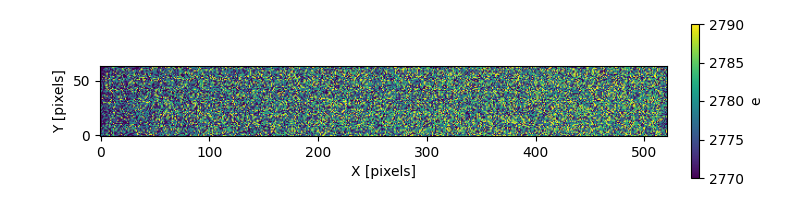

In [10]:
plt.figure(figsize=(8,2))

plt.imshow(bias00_data, vmin = 2770, vmax =2790, origin='lower')

cbar = plt.colorbar(fraction=0.046, pad=0.04)
cbar.set_label("e")

plt.xlabel('X [pixels]')
plt.ylabel('Y [pixels]')

plt.show()


## Save the bias frames into a 3D array

To compute the median for each pixel using all our frames, we need to open and save all the images in the RAM. 

We first check how many images we have by computing the length of the bias list - commented lines will not be included in the computation of the length.
We then retrieve the correct size of our frame according to how Python saved it in the computer's memory.
Finally, we make our empty array `stack` where we are going to store all the images.

In [11]:
n_images = len(bias_list)
bias00_nparray_dim00, bias00_nparray_dim01 = np.shape(bias00_data)

stack = np.empty([n_images, bias00_nparray_dim00, bias00_nparray_dim01])

We open the images one by one going through the list of file names using the Python built-in function [`enumerate`](https://docs.python.org/3/library/functions.html#enumerate).
When used within a `for` cycle as in the example below, for each element of the `iterable` (in this example, the list of fits names) the function will return the index of the element (i.e., its position inside the iterable) and the element itself. 

Within the cycle, we perform the following actions:
1) we open the `i_bias` bias using the `astropy.io.fits` function open 
2) we extract the data from the primary `[0]` HDU and convert it from ADU to *e* using the value of the GAIN in the header
3) we save the data in photoelectrons inside our stack, in the position `i_bias`
4) we close the file to free the RAM of the computer

Remember that the second and third axes of our `stack` have the same size of each image, assuming they are all identical.  

In [12]:
for i_bias, bias_name in enumerate(bias_list):
    bias_temp = fits.open('./group00_GJ3470_20220328/bias/'+bias_name)
    stack[i_bias,:,:] = bias_temp[0].data * bias_temp[0].header['GAIN']
    bias_temp.close()

We finally compute the median bias by calculating the median over all our frames (first axis) for each pixel (second and third axes). 

We use the median becuause it is more robust against outliers with respect to the average.

We use the NumPy [`median`](https://numpy.org/doc/stable/reference/generated/numpy.median.html) function, specifying that we want to compute the median only along the first axis. We do a final check by printing the shape of the median bias array and confirming that the shape is the same as the original bias frames. 


In [13]:
median_bias = np.median(stack, axis=0)
np.shape(median_bias)

(64, 521)

## Plotting a single bias and a median bias

We use the utility [`matplotlib.pyplot.subplots`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html) to include two plots in the same image. The first two values identify the number of rows andcolumns of the subplot grid (in the example, 2 plots one on top of the other, spanning the entire horizontal range). We pass the argument `figsize=(8,6)` to define the width and height of the plot, in inches. In geenral, we can pass every argument accepted by [matplotlib.pyplot.figure](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.figure.html).



We save each image to a new variable, `im1` and `im2`, so that we can use one of the image as reference for [`matplotlib.pyplot.colorbar`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.colorbar.html)

Finally, we specify the labels for each plot.

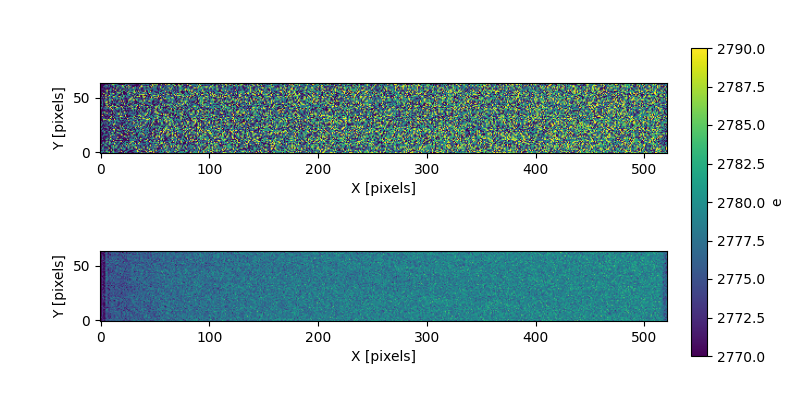

In [14]:
fig, ax = plt.subplots(2,1, figsize=(8,4)) # Caution, figsize will also influence positions.
im1 = ax[0].imshow(bias00_data, vmin = 2770, vmax =2790, origin='lower')
im2 = ax[1].imshow(median_bias, vmin = 2770, vmax =2790, origin='lower')

# add the colorbar using the figure's method,
# telling which mappable we're talking about and
# which axes object it should be near
cbar = fig.colorbar(im1, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("e")

ax[0].set_xlabel('X [pixels]')
ax[0].set_ylabel('Y [pixels]')

ax[1].set_xlabel('X [pixels]')
ax[1].set_ylabel('Y [pixels]')
plt.show()

## Statistical analysis of the bias
A bias frame comprises two primary components: the offset introduced by the electronics, and supposedly constant across the frame, and the readout noise.
We can then use the bias to extract some infomration regarding the readout noise.

First of all, let's verify if the bias is indeed constant across the frame. 
Visually, we can highlight any variation in the bias by restricting the range of the colorbar.
Analytically, we can compute the average across each column and plot the results as a function of the column number. We chose this way because the plot highlights a more substantial variation across the horizontal direction.

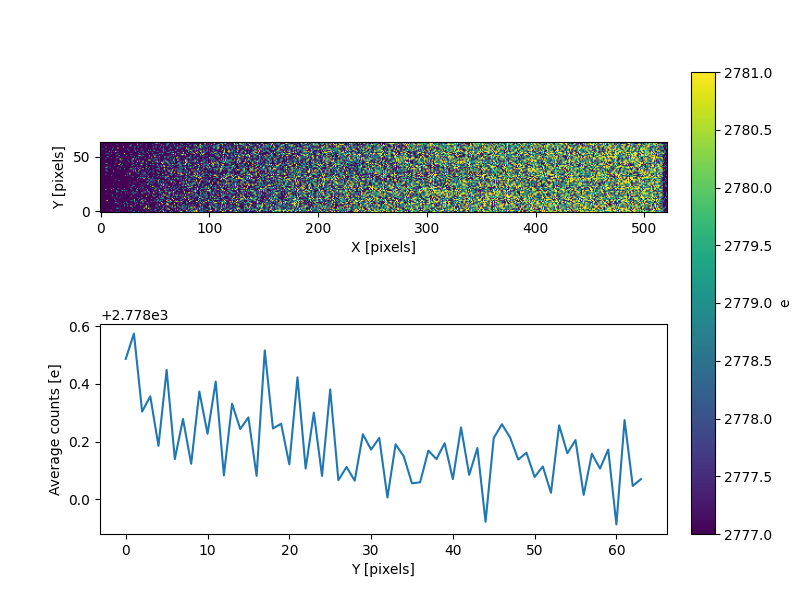

In [15]:
fig, ax = plt.subplots(2,1, figsize=(8,6)) # Caution, figsize will also influence positions.
im1 = ax[0].imshow(median_bias, vmin = 2777, vmax =2781, origin='lower')
median_row = np.average(median_bias, axis=1)
im2 = ax[1].plot(median_row)

# add the colorbar using the figure's method,
# telling which mappable we're talking about and
# which axes object it should be near
cbar = fig.colorbar(im1, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("e")

ax[0].set_xlabel('X [pixels]')
ax[0].set_ylabel('Y [pixels]')

ax[1].set_xlabel('Y [pixels]')
ax[1].set_ylabel('Average counts [e]')
plt.show()

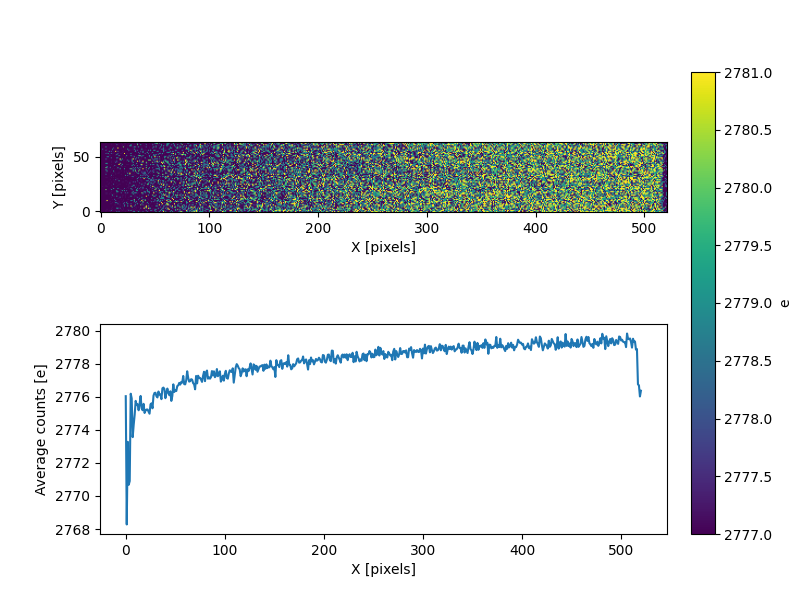

In [16]:
fig, ax = plt.subplots(2,1, figsize=(8,6)) # Caution, figsize will also influence positions.
im1 = ax[0].imshow(median_bias, vmin = 2777, vmax =2781, origin='lower')
median_column = np.average(median_bias, axis=0)
im2 = ax[1].plot(median_column)

# add the colorbar using the figure's method,
# telling which mappable we're talking about and
# which axes object it should be near
cbar = fig.colorbar(im1, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("e")

ax[0].set_xlabel('X [pixels]')
ax[0].set_ylabel('Y [pixels]')

ax[1].set_xlabel('X [pixels]')
ax[1].set_ylabel('Average counts [e]')
plt.show()

Knowing that the bias is not constant, we can still compare the readout noise as reported in the header of the fits frame and the standard deviation directly computed of the data if we restrict ourself to a small range in columns.

In [17]:
starting_column= 300
ending_column = 350
print('Readout noise                     : {0:4.2f} e'.format(bias00_readout_noise))
print('STD single frame, selected columns: {0:4.2f} e'.format(np.std(bias00_data[:,starting_column:ending_column])))

Readout noise                     : 7.10 e
STD single frame, selected columns: 7.75 e


The values above refer to the readout noise of a single exposure. The median bias is the combination of 30 individual frames, so the associated error will be smaller than the one coming with a single frame.

Suppose we approximate the median with the average function. In that case, we can use the standard equation for error propagation to compute the associated error to the median bias, assuming that all the pixels from each bias are affected by the same error. The resulting value will change slightly if we use the readout noise as an estimate of the error associated with each image (case 1) or if we use the standard deviation of a bias frame (case 2)

In [18]:
expected_noise_medianbias = bias00_readout_noise/np.sqrt(n_images)
print('1) Expected noise of median bias          : {0:4.2f} e'.format(expected_noise_medianbias))
expected_std_medianbias = np.std(bias00_data[:,starting_column:ending_column])/np.sqrt(n_images)
print('2) Expected STD of median bias (selection): {0:4.2f} e'.format(expected_std_medianbias))

1) Expected noise of median bias          : 1.30 e
2) Expected STD of median bias (selection): 1.42 e


Alternatively, we can compute the error associated with the median bias from the data. We can use the standard deviation of the median bias, selecting the same range in columns as done before (case 3), or we can compute the standard deviation of each pixel across all the frames, divide  by the square root of the number of images, and finally calculate the median of all these values. We perform the last step to have one value for the error associated with the median bias, but in principle, we could keep the entire frame.

In [19]:
measured_std_medianbias = np.std(median_bias[:,starting_column:ending_column])
print('Measured STD of median bias (selection): {0:4.2f} e'.format(measured_std_medianbias))
median_error = np.std(stack, axis=0) /np.sqrt(n_images)
median_pixel_error = np.median(median_error)
print('Median STD of each pixel               : {0:4.2f} e'.format(median_pixel_error))


Measured STD of median bias (selection): 1.75 e
Median STD of each pixel               : 1.37 e


We can see that the standard deviation computed on the median bias is slighlty higher than the associated error computed through the other techniques. 
We already analyzed the origin of this disagreement.  

Finally, we can plot the distribution of the error associated to each pixel of the median bias with the different estimates of the error. This plot should guide you towards the best choice fro the error to be associated to the median bias.

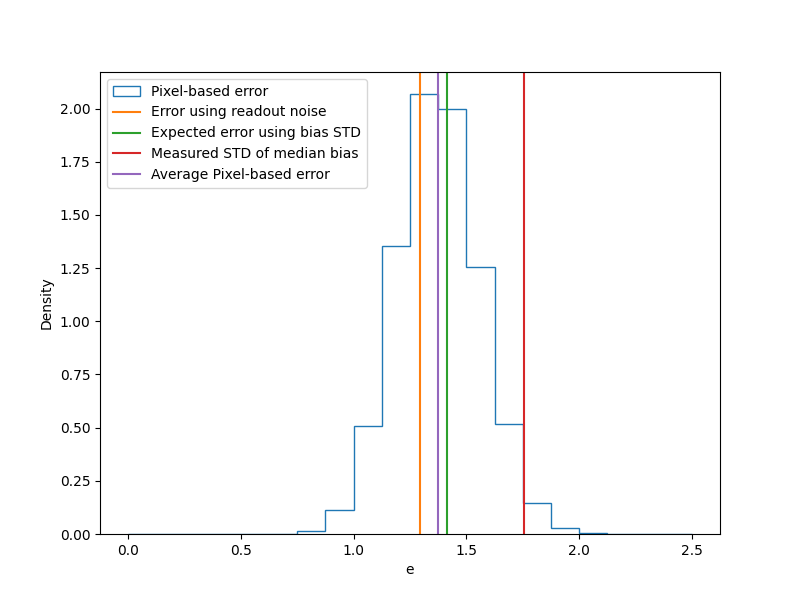

In [20]:
# Standard deviation of each pixel
STD_pixel = np.std(stack, axis=0) # 

plt.figure(figsize=(8,6))
plt.hist(median_error.flatten(), bins=20, range=(0,2.5), density=True, histtype='step', label='Pixel-based error')
plt.axvline(expected_noise_medianbias, c='C1', label='Error using readout noise')
plt.axvline(expected_std_medianbias, c='C2', label='Expected error using bias STD')
plt.axvline(measured_std_medianbias, c='C3', label='Measured STD of median bias')
plt.axvline(median_pixel_error, c='C4', label='Average Pixel-based error')
plt.xlabel('e')
plt.ylabel('Density')
plt.legend()
plt.show()

## Saving the output
We save our files using the [`pickle`](https://docs.python.org/3/library/pickle.html) module. This model allows the storage on disk of arrays as well as objects and dictionaries.

I provide an example of how to load a file into the notebook as well. Notice the different arguments for the `open` function (`wb` when writing, `rb` for reading) and the different structure of the command as well.


In [21]:
# Save a dictionary/object into a pickle file.
import pickle
  # create a dictionary
pickle.dump(median_bias, open("median_bias.p", "wb")) 
pickle.dump(median_error, open("median_bias_error.p", "wb")) 
pickle.dump(median_pixel_error, open("median_bias_error_value.p", "wb")) 
pickle.dump(stack, open("stack_bias.p", "wb")) 

In [22]:
median_bias = pickle.load(open("median_bias.p", "rb")) 
